## Data Analysis of the Data kindly provided by Dennis Halders
- 3 Different Co-cultivations with exometabolomics measurements but not comparable to each other
- One co-cultivation with axenic cultivations under the same condtions (run S008 E005)

1. OD data
2. Cell count
3. Exo-metabolomics
4. Combined figure for cell counts and sucrose concentration



### OD

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

filepath = "C:\\Users\\majas\\Desktop\\S008 E005 metadata.xlsx"
df = pd.read_excel(filepath, sheet_name="Metabolomics_culture_samples")

# coded with claude
df["time"] = pd.to_datetime(
    df["Parameter [Sampling date]"].str.replace(r"\s*\(.*\)$", "", regex=True),
    format="%a %b %d %Y %H:%M:%S GMT%z",
)
# in case different measurement timepoints were used for the same culture but in different days
df["hours"] = df.groupby('Input [Source Name]')["time"].transform(
    lambda t: (t - t.min()).dt.total_seconds() / 3600)

df["Culture"] = df["Input [Source Name]"].str.extract(r"culture_(\d+)").astype(int)

df_sorted = df.sort_values(by=["Culture", "hours"]).loc[:,["Culture", "hours","Characteristic [OD units]"]]

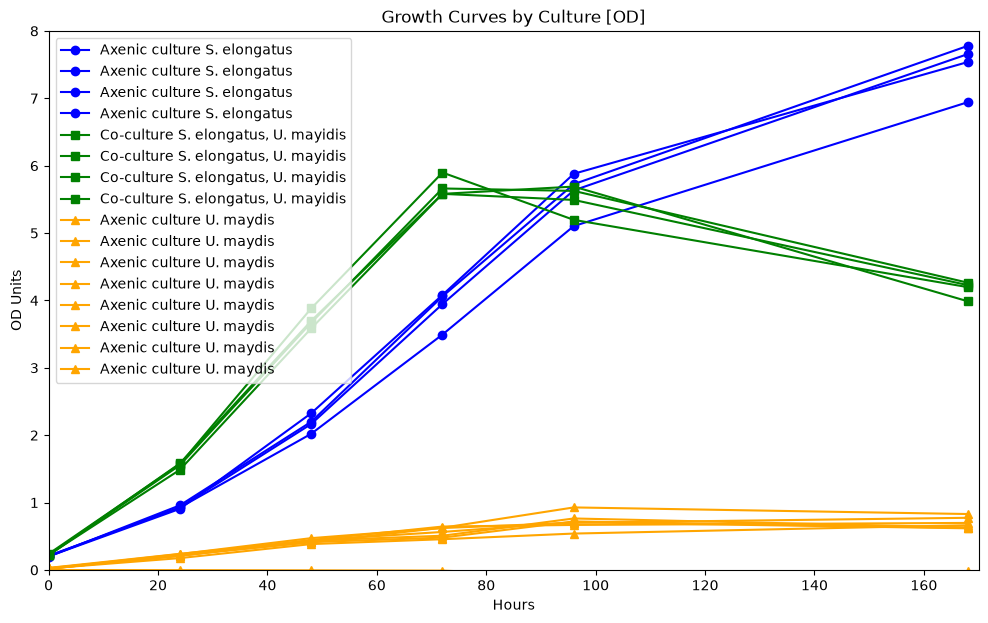

In [22]:
groups = df_sorted.groupby("Culture")

fig, ax = plt.subplots(figsize=(12, 7))
for name, group in groups:
    if name < 5:
        label = "Axenic culture S. elongatus"
        marker = "o"
        color = "blue"
    elif name < 9:
        label = "Co-culture S. elongatus, U. mayidis"
        marker = "s"
        color = "green"
    else:
        label = "Axenic culture U. maydis"
        marker = "^"
        color = "orange"
    ax.plot(group["hours"], group["Characteristic [OD units]"], marker=marker, label=label, color=color)
ax.set_xlim(0, 170)
ax.set_ylim(0,8)
ax.set_xlabel("Hours")
ax.set_ylabel("OD Units")
ax.set_title("Growth Curves by Culture [OD]")
ax.legend()
plt.show()

### Cell Counting

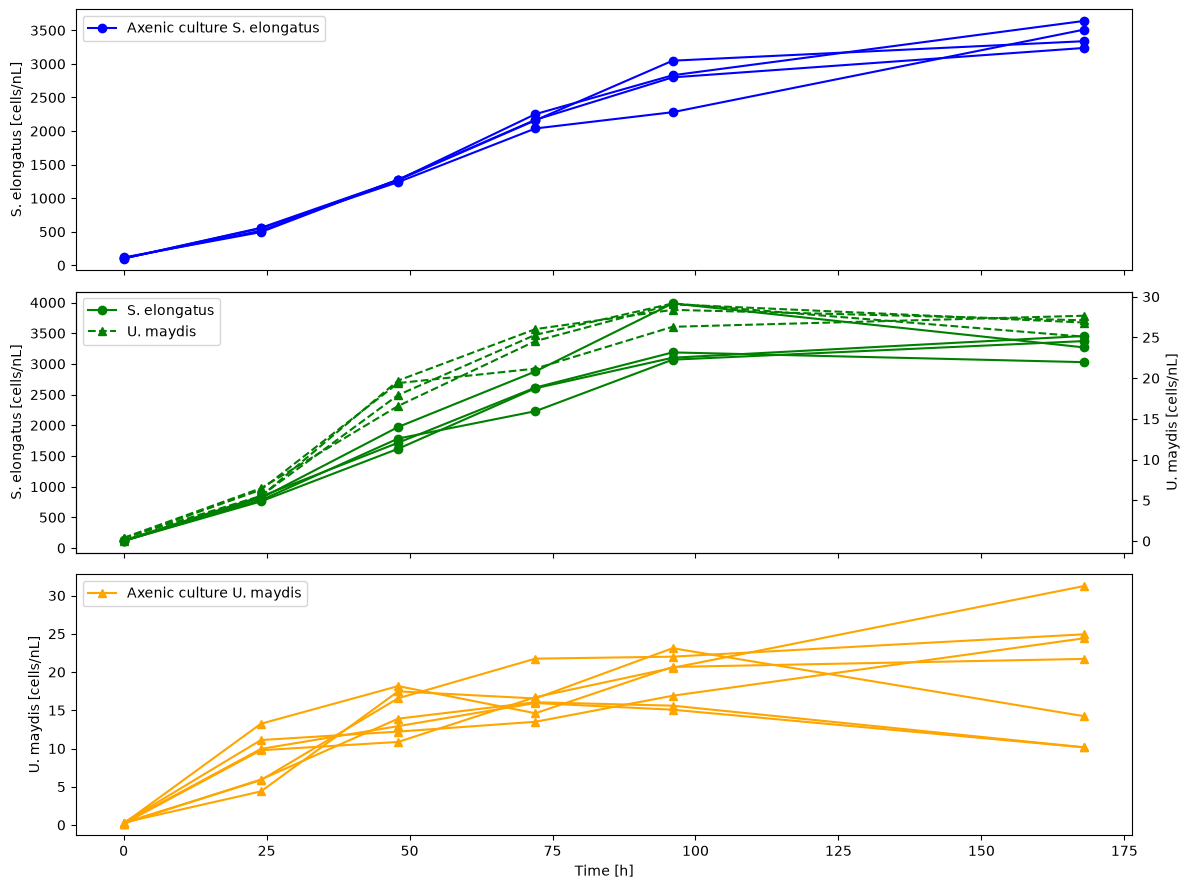

In [23]:
# for a first impression this was coded with the help of AI
filepath = "C:\\Users\\majas\\Desktop\\data\\runs\\S008_E005DH\\cytometry_results\\S008_E005_cytometry_concentration_export.xlsx"
df_2 = pd.read_excel(filepath, sheet_name="Sheet1")
df_2["Culture"] = df_2["biological_sample_name"].astype(int)
groups = sorted(df_2.groupby("Culture"))

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

ax1_uma = ax[1].twinx()
seen = set()

for name, group in groups:
    g = group.groupby("sampling_time_[h]", as_index=False).mean(numeric_only=True)
    t = g["sampling_time_[h]"]

    if name < 5:
        label, marker, color = "Axenic culture S. elongatus", "o", "blue"
        lbl = None if label in seen else label; seen.add(label)
        ax[0].plot(t, g["7942_total_concentration_[cells/nL]"],
                   marker=marker, color=color, label=lbl)

    elif name < 9:
        color = "green"
        l1 = None if "co_7942" in seen else "S. elongatus"; seen.add("co_7942")
        l2 = None if "co_uma"  in seen else "U. maydis";    seen.add("co_uma")
        ax[1].plot(t, g["7942_total_concentration_[cells/nL]"],
                   marker="o", color=color, label=l1)
        ax1_uma.plot(t, g["UMa_total_concentration_[cells/nL]"],
                     marker="^", color=color, linestyle="--", label=l2)

    elif name < 16: # 16 seems to be a negative control
        label, marker, color = "Axenic culture U. maydis", "^", "orange"
        lbl = None if label in seen else label; seen.add(label)
        ax[2].plot(t, g["UMa_total_concentration_[cells/nL]"],
                   marker=marker, color=color, label=lbl)

# 4: ax ist ein Array -- die Panels einzeln ansprechen
ax[0].set_ylabel("S. elongatus [cells/nL]")
ax[1].set_ylabel("S. elongatus [cells/nL]")
ax1_uma.set_ylabel("U. maydis [cells/nL]")
ax[2].set_ylabel("U. maydis [cells/nL]")
ax[2].set_xlabel("Time [h]")

ax[0].legend()
ax[1].legend(*[a + b for a, b in zip(ax[1].get_legend_handles_labels(),
                                     ax1_uma.get_legend_handles_labels())])
ax[2].legend()

fig.tight_layout()
plt.show()

#### calculate the Biomassconcentration out of this:

Daniel Ducant -> 

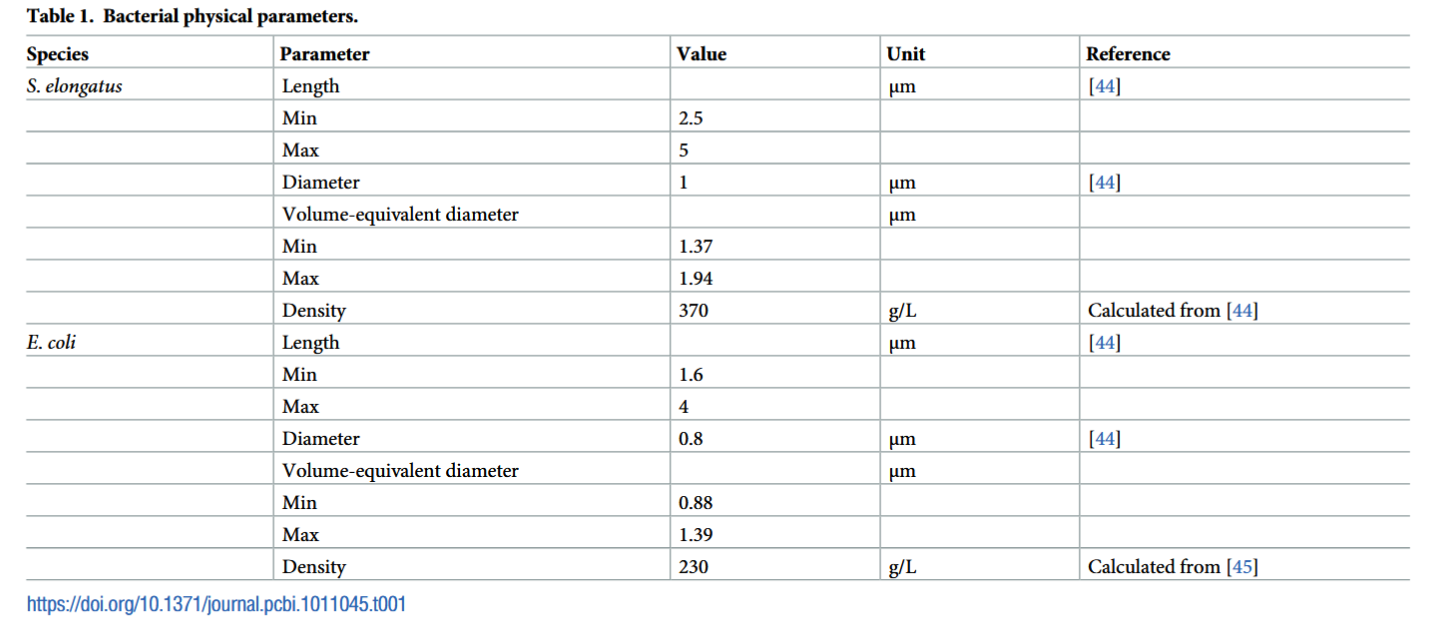

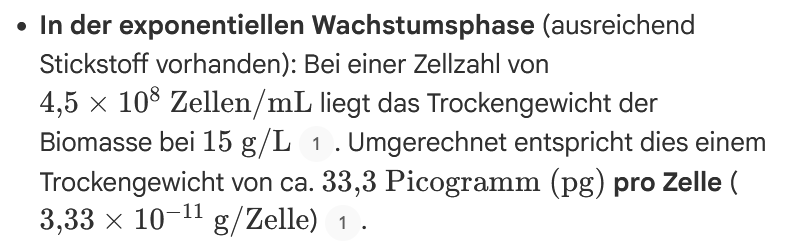
1 = https://doi.org/10.1186/1475-2859-11-43

In [24]:
##  U. maydis = 33,3 pg/cell 
dry_w_U_may= 33.3*10**(-12)
## calculate by Volume equivalent diameter -> Kugel * Density
## 4/3* r**3 *pi
dry_w_S_elong= 4/3*((1.37/1.94)*10**(-6)/2)**3*3.1314 *370*10**3
# 0.068 pg/cell



### Metabolomics

In [25]:
filepath = "C:\\Users\\majas\\Desktop\\data\\runs\\S008_E005DH\\metabolomics\\0-168h_final\\25-0049_s05_a06_results.xlsx"
df_3 = pd.read_excel(filepath, sheet_name="Sheet1").loc[:, ["Culture", "Compound", "TimePoint", "rel.conc", "Characteristic [pH]"]]

axenic_se = df_3[df_3["Culture"]== "Axenic 7942"]
medium = df_3[df_3["Culture"]== "Medium"]
coculture = df_3[df_3["Culture"]== "Co-culture"]
axenic_uma = df_3[df_3["Culture"]== "Axenic UMa"]

touple_list = [
    ("Axenic S. elongatus",     axenic_se),
    ("Co-culture S. elongatus", coculture),
    ("Medium",    medium),
    ("Axenic U. maydis",        axenic_uma),
]

df_list=[]
std_list=[]
for name, culture in touple_list:
    collecting_dict={}
    for compound in culture["Compound"].unique():
        mean = culture[culture["Compound"]==compound].groupby(["TimePoint"])["rel.conc"].mean()
        std = culture[culture["Compound"]==compound].groupby(["TimePoint"])["rel.conc"].std()
        std_normalized= std/mean
        collecting_dict[str(compound)+" mean"]= mean
        collecting_dict[str(compound)+" std"]= std
        if name != "Medium":
            std_list.append([compound,mean.mean(),std.mean(), std_normalized.median()])
    df_list.append(pd.DataFrame(collecting_dict))

met_axenic_se= df_list[0] 
met_coculture= df_list[1] 
met_medium= df_list[2]
met_axenic_uma= df_list[3]

print(f"{int(len(met_coculture.columns)/2)} metabolites were measured")


28 metabolites were measured


Final Figure Comining metabolomics and cell counting

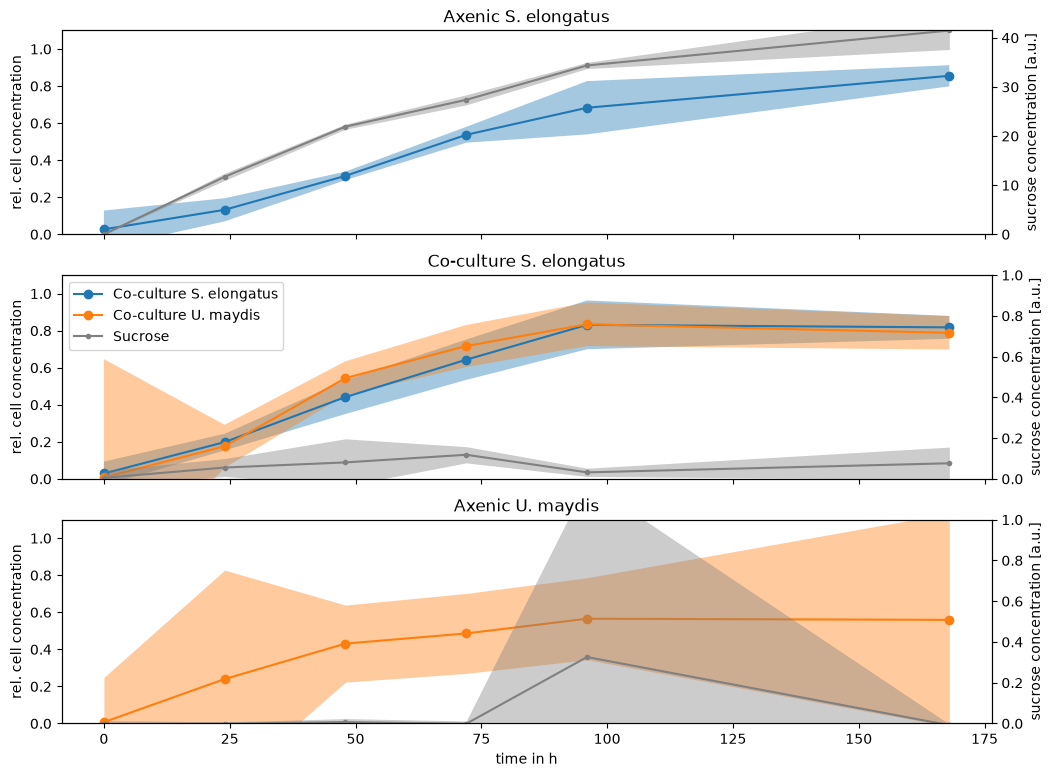

In [38]:
filepath = "C:\\Users\\majas\\Desktop\\data\\runs\\S008_E005DH\\cytometry_results\\S008_E005_cytometry_concentration_export.xlsx"
df_2 = pd.read_excel(filepath, sheet_name="Sheet1")
df_2["Culture"] = df_2["biological_sample_name"].astype(int)
groups = sorted(df_2.groupby("Culture"))

# define the cultivations and their biological replicates
axenic_se = df_2[df_2["Culture"] < 5]
coculture = df_2[(df_2["Culture"] >= 5) & (df_2["Culture"] < 9)]
axenic_uma = df_2[(df_2["Culture"] >= 9) & (df_2["Culture"] < 16)]

# maybe for later usage: Normalization + % std 
# -> normalization against the highest reached cell count in all experiments of one species
max_se= df_2["7942_total_concentration_[cells/nL]"].max()
max_uma= df_2["UMa_total_concentration_[cells/nL]"].max()

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

touple_list = [
    ("Axenic S. elongatus",     axenic_se, "7942_total_concentration_[cells/nL]"),
    ("Co-culture S. elongatus", coculture,  "7942_total_concentration_[cells/nL]"),
    ("Co-culture U. maydis",    coculture,  "UMa_total_concentration_[cells/nL]"),
    ("Axenic U. maydis",        axenic_uma,  "UMa_total_concentration_[cells/nL]"),
]
collecting_dict={}
collecting_dict_normalized={}
i =0
collecting_std=[]
for name, culture_df, column in touple_list:
    mean = culture_df.groupby("sampling_time_[h]")[column].mean()
    mean_normalized = mean/df_2[column].max() 
    collecting_dict_normalized[name + " mean"]= mean_normalized
    collecting_dict[name + " mean"]= mean
    std = culture_df.groupby("sampling_time_[h]")[column].std()
    std_normalized= std/mean
    collecting_std.append([std, std_normalized, mean])
    collecting_dict[name + " std"]= std
    collecting_dict_normalized[name + " std"]= std_normalized
    if i==0:
        ax[0].plot(mean.index, mean_normalized,label=name, marker="o")
        ax[0].fill_between(mean.index,mean_normalized - std_normalized, mean_normalized + std_normalized, alpha=0.4, linewidth=0)
        ax[0].set_title("Axenic S. elongatus")
    elif i==1 or i==2:
        ax[1].plot(mean.index, mean_normalized, label=name, marker="o")
        ax[1].fill_between(mean.index,mean_normalized - std_normalized, mean_normalized + std_normalized, alpha=0.4, linewidth=0)
        ax[1].set_title("Co-culture S. elongatus")
    elif i ==3:
        ax[2].plot(mean.index, mean_normalized, label=name, marker="o", color="C1")
        ax[2].fill_between(mean.index,mean_normalized - std_normalized, mean_normalized + std_normalized, alpha=0.4, linewidth=0,color="C1") 
        ax[2].set_title("Axenic U. maydis")
    i+=1

cell_counts =pd.DataFrame(collecting_dict)
cell_counts_normalized = pd.DataFrame(collecting_dict_normalized)

# finishing the figure:
met_df_list=[met_axenic_se, met_coculture, met_axenic_uma]
for num,axis in enumerate(ax):
    ax_sucrose= axis.twinx()
    suc_mean = met_df_list[num].loc[:,"Sucrose mean"]-met_medium.loc[:,"Sucrose mean"]
    suc_std = met_df_list[num].loc[:,"Sucrose std"]
    ax_sucrose.plot(mean.index, suc_mean, marker=".", color="gray", label="Sucrose")
    ax_sucrose.fill_between(mean.index,suc_mean - suc_std, suc_mean + suc_std, alpha=0.4, linewidth=0, color="gray")
    ax_sucrose.set_ylim(0,max(max(suc_mean),1))
    ax_sucrose.set_ylabel("sucrose concentration [a.u.]")
    axis.set_ylim(0,1.1)
    axis.set_ylabel("rel. cell concentration")
    met_df_list=[met_axenic_se, met_coculture, met_axenic_uma]
    if num == 1:
        handles1, labels1 = axis.get_legend_handles_labels()
        handles2, labels2 = ax_sucrose.get_legend_handles_labels()
        axis.legend(handles1 + handles2, labels1 + labels2, loc="best")
    if num == 2:
        axis.set_xlabel("time in h")
        



In [37]:
cell_counts

,Axenic S. elongatus mean,Axenic S. elongatus std,Co-culture S. elongatus mean,Co-culture S. elongatus std,Co-culture U. maydis mean,Co-culture U. maydis std,Axenic U. maydis mean,Axenic U. maydis std
sampling_time_[h],,,,,,,,
0.0,107.826375,10.942400,117.664011,7.539092,0.272993,0.174326,0.245861,0.059365
24.0,530.652336,33.165308,796.726785,35.887324,5.950057,0.689929,8.113313,4.771152
48.0,1265.574746,29.223705,1772.119457,161.933572,18.402219,1.675264,14.584973,3.032910
72.0,2154.757216,92.437716,2580.815172,281.301947,24.260735,2.753435,16.443490,3.548656
96.0,2739.991083,394.129830,3335.538677,439.148127,28.228480,3.325400,19.130085,4.230454
168.0,3432.334460,196.237852,3280.816077,202.640534,26.667022,2.402772,18.918938,10.884572


In [28]:
# Important metrics to determine the expected standard deviation and data scarcity 
timepoints = list(mean.index.astype(int))
print(f"{len(timepoints)} Timepoints available: {timepoints}")
std_array = np.array(collecting_std)
std_normalized_mean = np.median(std_array[:, 1])
print(f"Median of normalized standard deviation of cell counts: {std_normalized_mean}")
std_df = pd.DataFrame(std_list, columns=["Compound", "mean", "std", "std_normalized"])
approximated_detection_limit =  0.01
std_norm = std_df["std_normalized"][std_df["mean"] >= approximated_detection_limit].median()
print(f"Median of Coefficient of Variation of all compounds and all cultures if relative concentration above {approximated_detection_limit}: {std_norm}")

6 Timepoints available: [0, 24, 48, 72, 96, 168]
Median of normalized standard deviation of cell counts: 0.11124539296933542
Median of Coefficient of Variation of all compounds and all cultures if relative concentration above 0.01: 0.21567399229358863


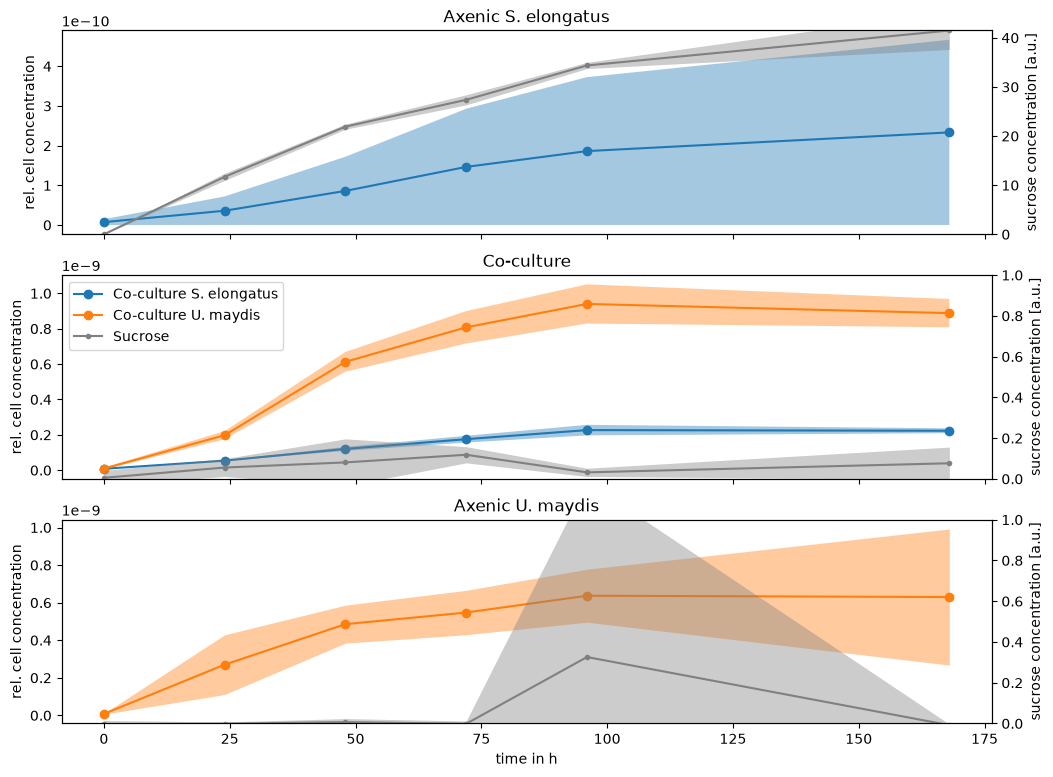

In [29]:
filepath = "C:\\Users\\majas\\Desktop\\data\\runs\\S008_E005DH\\cytometry_results\\S008_E005_cytometry_concentration_export.xlsx"
df_2 = pd.read_excel(filepath, sheet_name="Sheet1")
df_2["Culture"] = df_2["biological_sample_name"].astype(int)
groups = sorted(df_2.groupby("Culture"))

# define the cultivations and their biological replicates
axenic_se = df_2[df_2["Culture"] < 5]
coculture = df_2[(df_2["Culture"] >= 5) & (df_2["Culture"] < 9)]
axenic_uma = df_2[(df_2["Culture"] >= 9) & (df_2["Culture"] < 16)]

# maybe for later usage: Normalization + % std 
# -> normalization against the highest reached cell count in all experiments of one species
max_se= df_2["7942_total_concentration_[cells/nL]"].max()
max_uma= df_2["UMa_total_concentration_[cells/nL]"].max()

fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

touple_list = [
    ("Axenic S. elongatus",     axenic_se, "7942_total_concentration_[cells/nL]"),
    ("Co-culture S. elongatus", coculture,  "7942_total_concentration_[cells/nL]"),
    ("Co-culture U. maydis",    coculture,  "UMa_total_concentration_[cells/nL]"),
    ("Axenic U. maydis",        axenic_uma,  "UMa_total_concentration_[cells/nL]"),
]
i=0
for name, culture_df, column in touple_list:
    mean = culture_df.groupby("sampling_time_[h]")[column].mean() 
    std = culture_df.groupby("sampling_time_[h]")[column].std()
    if i==0:
        mean_weight = mean*dry_w_S_elong 
        std_weigth = mean*dry_w_S_elong
        ax[0].plot(mean.index, mean_weight,label=name, marker="o")
        ax[0].fill_between(mean.index,mean_weight - std_weigth, mean_weight + std_weigth, alpha=0.4, linewidth=0)
        ax[0].set_title("Axenic S. elongatus")
    elif i==1:
        mean_weight = mean*dry_w_S_elong 
        std_weigth = std*dry_w_S_elong
        ax[1].plot(mean.index, mean_weight, label=name, marker="o")
        ax[1].fill_between(mean.index,mean_weight - std_weigth, mean_weight + std_weigth, alpha=0.4, linewidth=0)
    elif i==2:
        mean_weight = mean*dry_w_U_may
        std_weigth = std*dry_w_U_may
        ax[1].plot(mean.index, mean_weight, label=name, marker="o")
        ax[1].fill_between(mean.index,mean_weight - std_weigth, mean_weight + std_weigth, alpha=0.4, linewidth=0)
        ax[1].set_title("Co-culture")
    elif i ==3:
        mean_weight = mean*dry_w_U_may
        std_weigth = std*dry_w_U_may
        ax[2].plot(mean.index, mean_weight, label=name, marker="o", color="C1")
        ax[2].fill_between(mean.index,mean_weight - std_weigth, mean_weight + std_weigth, alpha=0.4, linewidth=0,color="C1") 
        ax[2].set_title("Axenic U. maydis")
    i+=1

# finishing the figure:
met_df_list=[met_axenic_se, met_coculture, met_axenic_uma]
for num,axis in enumerate(ax):
    ax_sucrose= axis.twinx()
    suc_mean = met_df_list[num].loc[:,"Sucrose mean"]-met_medium.loc[:,"Sucrose mean"]
    suc_std = met_df_list[num].loc[:,"Sucrose std"]
    ax_sucrose.plot(mean.index, suc_mean, marker=".", color="gray", label="Sucrose")
    ax_sucrose.fill_between(mean.index,suc_mean - suc_std, suc_mean + suc_std, alpha=0.4, linewidth=0, color="gray")
    ax_sucrose.set_ylim(0,max(max(suc_mean),1))
    ax_sucrose.set_ylabel("sucrose concentration [a.u.]")
    #axis.set_ylim(0,1.1)
    axis.set_ylabel("rel. cell concentration")
    met_df_list=[met_axenic_se, met_coculture, met_axenic_uma]
    if num == 1:
        handles1, labels1 = axis.get_legend_handles_labels()
        handles2, labels2 = ax_sucrose.get_legend_handles_labels()
        axis.legend(handles1 + handles2, labels1 + labels2, loc="best")
    if num == 2:
        axis.set_xlabel("time in h")

In [89]:
# for a first impression this was coded with the help of AI
# "C:\\Users\\majas\\Desktop\\data\\runs\\S010_E004DH\\metabolomics_results\\25-0049_s04_a04_normalized_data.xlsx"
filepath = "C:\\Users\\majas\\Desktop\\data\\runs\\S010_E004DH\\cytometry_results\\S010_E004_cytometry_concentration_export.xlsx"
df_2 = pd.read_excel(filepath, sheet_name="Sheet1")

In [70]:
df_2

,biological_sample_name,sample_number,sampling_time_[h],dilution_factor,volume_[nL],7942_total_concentration_[cells/nL],UMa_eGFP_total_concentration_[cells/nL],7942_UMa_eGFP_doublets_concentration_[cells/nL],7942_singlets_concentration_[cells/nL],UMa_eGFP_singlets_concentration_[cells/nL]
0,1,1,70,100,5010.571,282.382986,0.039916,0.039916,282.343070,0.000000
1,1,1,70,200,5009.435,268.653052,0.039925,0.039925,268.613127,0.000000
2,1,1,70,100,5006.269,263.749311,0.079900,0.079900,263.669411,0.000000
3,1,1,70,200,5010.206,260.308658,0.000000,0.000000,260.308658,0.000000
4,1,1,70,100,5010.219,250.987033,0.000000,0.000000,250.987033,0.000000
...,...,...,...,...,...,...,...,...,...,...
99,1,13,430,200,5013.749,218.279774,0.079781,0.039890,218.239884,0.039890
100,1,13,430,100,5008.263,219.337523,0.079868,0.039934,219.297589,0.039934
101,1,13,430,200,5010.877,211.978861,0.079826,0.079826,211.899035,0.000000
102,1,13,430,100,5015.203,215.783888,0.039879,0.019939,215.763948,0.019939


In [78]:
df_2_mean = df_2.groupby("sampling_time_[h]").mean()

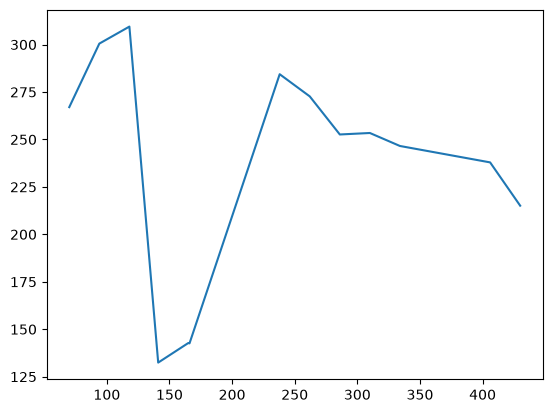

In [102]:
Se= np.array(df_2_mean["7942_total_concentration_[cells/nL]"])
time = df_2_mean.index
Um = np.array(df_2_mean["UMa_eGFP_total_concentration_[cells/nL]"]*3.81653)
together= Se+Um
plt.plot(time,together )

In [ ]:
sum(df_2.groupby("sampling_time_[h]").std()["7942_total_concentration_[cells/nL]"])
df_2.groupby("sampling_time_[h]").std()["7942_total_concentration_[cells/nL]"]
std= df_2.groupby("sampling_time_[h]").std()
np.mean(std["UMa_eGFP_total_concentration_[cells/nL]"])*

np.float64(0.21447924511968502)

In [ ]:
print(df_2.groupby("sampling_time_[h]").size())

In [ ]:
import numpy as np

A = df[["z", "y"]].to_numpy()
(j, i), *_ = np.linalg.lstsq(A, df["b"].to_numpy(), rcond=None)

res = df["b"] - (j * df["z"] + i * df["y"])     # Fehler je Zeile
r2 = 1 - (res**2).sum() / ((df["b"] - df["b"].mean())**2).sum()

print(f"j = {j:.6g}\ni = {i:.6g}")
print(f"RMSE = {np.sqrt(np.mean(res**2)):.6g}, R² = {r2:.4f}")

In [117]:
# for a first impression this was coded with the help of AI
# "C:\\Users\\majas\\Desktop\\data\\runs\\S010_E004DH\\metabolomics_results\\25-0049_s04_a04_normalized_data.xlsx"
filepath = "C:\\Users\\majas\\Desktop\\data\\runs\\S010_E004DH\\metabolomics_results\\25-0049_s04_a04_normalized_data.xlsx"
df_3 = pd.read_excel(filepath, sheet_name="Sheet1")
df_3_mean = df_3.loc[:,["Characteristic [OD units]","Input [Source Name]"]].groupby("Input [Source Name]").mean()

In [119]:
len(df_3_mean.index)-len(df_2_mean.index)

0

In [107]:
df_3.columns["Input [Source Name]"]

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

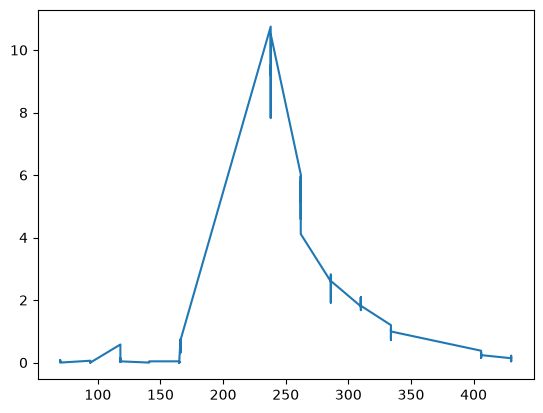

In [72]:
plt.plot(time, Um)